# KPP–Fisher in 2-D

This example is a continuation of [`kpp_fisher_1d`](kpp_fisher_1d.ipynb). The essential difference
in the subscript logic is the multiple indexing. The logic that applies to `u[i]` on a chain
similarly applies to `u[a, b]` using the same API.

:::{seealso}
- [`kpp_fisher_1d`](kpp_fisher_1d.ipynb) has the derivations and the figures, and expands the
  abbreviation **CL**, Carleman linearization. Read that page first.
:::

| | 1-D | here |
|---|---|---|
| right-hand side | 3-point Laplacian | 5-point Laplacian |
| grid | chain | $8\times8$ solved; assembly timed to $12\times12$ |
| degree | 3 | 2 |
| read-out bonds per site | up to 2 | up to 4 |
| `find_reachable_bras`, `classify_by_shift`, `build` | derived, with a figure each | **identical**, copied so this runs alone |

Only the right-hand side and the read-out differ below.


## Assembly

The assembly functions below are copied from [`kpp_fisher_1d`](kpp_fisher_1d.ipynb) unchanged, with
the imports trimmed to what this notebook uses.

They are here so that this notebook runs on its own. The reasoning and the figures stay in
[`kpp_fisher_1d`](kpp_fisher_1d.ipynb).


In [1]:
import time

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.sparse import csc_matrix, csr_matrix
from scipy.sparse.linalg import expm_multiply
from scipy.integrate import solve_ivp

from lin_ode.basis import CarlemanBasis, CarlemanState
from lin_ode import OperatorMatrix
from lin_ode.operators import Koopman
from lin_ode import OrdinaryDifferentialSystem
from collections.abc import Iterator

from lin_ode.vector import Vector

D, Q, R, h = sp.symbols("D Q R h", positive=True)
u = sp.IndexedBase("u")  # field symbol; the basis supplies only the sites and powers

# lin_ode takes a grid site as its plain coordinate tuple, so a site *is* its coordinates.
# coord() exists only because lin_ode reports a 1-D site as a bare scalar i, not (i,).


def coord(label):  # site label -> integer coordinate tuple (wraps the bare 1-D scalar)
    return tuple(int(v) for v in label) if isinstance(label, (sp.Tuple, tuple)) else (int(label),)


def as_monomial(*factors):  # CarlemanState((site, power), ...) -> u[site]**power * ...
    return sp.Mul(*[u[coord(site)] ** power for site, power in factors])

StateLabel = tuple[tuple[int, int], ...]  # a state, as its (site, power) factors
CanonicalFactors = tuple[tuple[tuple[int, ...], int], ...]  # ((coordinates, power), ...), sorted
CouplingKey = tuple[CanonicalFactors, CanonicalFactors]  # (bra, ket), what classify_by_shift returns

In [2]:
def as_factors(state: CarlemanState) -> StateLabel:
    """A CarlemanState as canonical (coordinate-tuple, power) factors."""
    return tuple((coord(label), int(power)) for label, power in state.args)


def iter_neighbours(site: tuple[int, ...], shape: tuple[int, ...]) -> Iterator[tuple[int, ...]]:
    """The in-grid ±1 neighbours of `site`, one per axis and direction.

    Out-of-grid neighbours are simply not yielded, which is the Dirichlet end.
    """
    for axis, size in enumerate(shape):
        shifted = list(site)
        for step in (-1, 1):
            shifted[axis] = site[axis] + step
            if 0 <= shifted[axis] < size:
                yield tuple(shifted)


def find_reachable_bras(ket: StateLabel, shape: tuple[int, ...], degree: int) -> set[StateLabel]:
    """Bras a ket couples to: itself, one diffusion hop, and the reaction term."""
    state = CarlemanState(*ket)
    bras = {as_factors(state)}
    total_degree = sum(power for _, power in ket)

    for label, power in ket:
        for site in iter_neighbours(coord(label), shape):          # diffusion
            hopped = state.update_dim(label, power - 1)
            bras.add(as_factors(hopped.update_dim(site, state.get_n(site) + 1)))
        if total_degree < degree:                             # reaction
            bras.add(as_factors(state.update_dim(label, power + 1)))
    return bras

In [3]:
def canonicalise_positions(sites: list[tuple[int, ...]], radius: int) -> list[dict[int, int]]:
    """Per axis, a map from each occurring coordinate to its canonical position.

    Gaps wider than the stencil radius are capped at `radius + 1`, because sites
    farther apart than the radius do not interact.
    """
    maps = []
    for axis in range(len(sites[0])):
        present = sorted({site[axis] for site in sites})
        position, axis_map = 0, {}
        for rank, value in enumerate(present):
            if rank:
                position += min(value - present[rank - 1], radius + 1)
            axis_map[value] = position
        maps.append(axis_map)
    return maps


def classify_by_shift(bra: StateLabel, ket: StateLabel, radius: int = 1) -> CouplingKey:
    """Shift-canonical key of a (bra, ket) coupling; equal keys share the same value."""
    sites = [coord(label) for label, _ in bra + ket]
    if not sites:
        return (), ()
    relabel = canonicalise_positions(sites, radius)

    def canonical(factors: StateLabel) -> CanonicalFactors:
        return tuple(sorted(
            (tuple(m[c] for m, c in zip(relabel, coord(label))), power)
            for label, power in factors
        ))

    return canonical(bra), canonical(ket)

In [4]:
def build(
    matrix: OperatorMatrix, basis: CarlemanBasis
) -> tuple[dict[tuple[int, int], sp.Expr], dict[tuple, sp.Expr]]:
    """Assemble the sparse generator {(bra, ket): value}, calling M[bra,ket] once per classify_by_shift."""
    shape, degree = coord(basis.n_vars), basis.degree  # the basis already carries the grid and truncation
    entries, value = {}, {}
    for ket_flat in range(len(basis)):
        ket = basis.structured_idx_of_flat_index(ket_flat)
        for bra in find_reachable_bras(ket, shape, degree):
            key = classify_by_shift(bra, ket)
            if key not in value:
                value[key] = matrix[bra, ket]  # <-- M[bra, ket], once per shape
            if value[key] != 0:
                entries[(basis.flat_index_of_structured_index(bra), ket_flat)] = value[key]
    return entries, value


def carleman_matrix(entries: dict[tuple[int, int], sp.Expr], dim: int) -> csc_matrix:
    """Carleman matrix A = M^T from the sparse generator entries {(bra, ket): value}."""
    rows, cols = zip(*entries)
    data = [float(val) for val in entries.values()]  # real coefficients, real field: no complex anywhere
    return csr_matrix((data, (rows, cols)), shape=(dim, dim)).T.tocsc()

## The 2-D right-hand side

Same equation, 5-point Laplacian:

$$\frac{du_{i,j}}{dt}=\frac{D\,(u_{i-1,j}+u_{i+1,j}+u_{i,j-1}+u_{i,j+1}-4u_{i,j})}{h^{2}}
+Q\,u_{i,j}+R\,u_{i,j}^{2}.$$

`shape` and `box` simply grow a second entry; `find_reachable_bras` walks both axes because
`iter_neighbours` does.

In [5]:
def fisher_2d(n: int) -> OrdinaryDifferentialSystem:
    """2-D Fisher-KPP (5-point Laplacian) on an n x n grid, Dirichlet on all four sides.

    Index arithmetic wraps by default, so each arm of the stencil has to say that it
    reads 0 where it leaves the grid, which is u = 0 outside it.
    """
    field = sp.IndexedBase("u")
    row = sp.Idx("i", (0, n - 1))
    col = sp.Idx("j", (0, n - 1))

    def arm(index, step, other, axis):  # 0 off the grid, the neighbour on it
        shifted = index + step
        site = (shifted, other) if axis == 0 else (other, shifted)
        on_the_grid = shifted >= 0 if step == -1 else shifted <= n - 1
        return sp.Piecewise((field[site], on_the_grid), (0, sp.true))

    laplacian = (
        arm(row, -1, col, 0) + arm(row, +1, col, 0)
        + arm(col, -1, row, 1) + arm(col, +1, row, 1)
        - 4 * field[row, col]
    ) / h**2
    rhs = sp.piecewise_fold(D * laplacian + Q * field[row, col] + R * field[row, col] ** 2)
    return OrdinaryDifferentialSystem.from_sympy(rhs, field, (row, col))

for n in (5, 8, 12):
    basis = CarlemanBasis((n, n), 2)
    matrix = OperatorMatrix(basis, Koopman().create_operator(fisher_2d(n)))
    t = time.time()
    entries, value = build(matrix, basis)
    print(f"2-D {n:2d}x{n:<2d}: dim={len(basis):5d}  nonzeros={len(entries):6d}  M[bra,ket] calls={len(value):3d}  {time.time()-t:4.1f}s")

2-D  5x5 : dim=  351  nonzeros=  2455  M[bra,ket] calls=140  44.5s


2-D  8x8 : dim= 2145  nonzeros= 16768  M[bra,ket] calls=140  44.9s


2-D 12x12: dim=10585  nonzeros= 87288  M[bra,ket] calls=140  47.4s


## 2-D: CL vs exact heatmaps

8×8 grid, degree 2, IC $u(0)=\sin^2(\pi x)\sin^2(\pi y)$, $T=0.1$.

### Building the generator

The 5-point-Laplacian generator, built as in 1-D, then transposed: $A=M^{\mathsf T}$.

In [6]:
n, degree, T = 8, 2, 0.1
nums = {D: 1, Q: 1, R: -1, h: sp.Rational(1, n)}
eq = fisher_2d(n).equation
ode = OrdinaryDifferentialSystem.from_sympy(eq.expr.subs(nums), eq.state_variable, eq.indices)
basis = CarlemanBasis((n, n), degree)
matrix = OperatorMatrix(basis, Koopman().create_operator(ode))

entries, value = build(matrix, basis)
A = carleman_matrix(entries, len(basis))
print(f"A = M^T: dim={A.shape[0]}, from {len(value)} M[bra,ket] calls")

A = M^T: dim=2145, from 140 M[bra,ket] calls


### The initial condition

The 2-D bump, with each basis monomial evaluated at it to give $\boldsymbol\Phi(0)$.

`deg1[a][b]` locates $u_{a,b}$.

In [7]:
xg = np.arange(n) / n
bump = 0.5 - 0.5 * np.cos(2 * np.pi * xg)
u0 = np.outer(bump, bump)

# same two steps as in 1-D; a grid site is addressed as u[a, b]
values = {u[a, b]: u0[a, b] for a in range(n) for b in range(n)}
Phi0 = np.array(
    [
        float(basis[idx].replace(CarlemanState, as_monomial).subs(values))
        for idx in map(basis.structured_idx_of_flat_index, range(len(basis)))
    ]
)
deg1 = [[basis.flat_index_of_basis_function(basis.state_type(((a, b), 1))) for b in range(n)] for a in range(n)]

### The Carleman solution

Evolve, then read $\boldsymbol\Phi_1$ back onto the grid at 6 times.

In [8]:
times = np.linspace(0, T, 6)
traj = expm_multiply(A, Phi0, start=0, stop=T, num=6, endpoint=True)
cl = traj[:, deg1]  # deg1 is n x n, so this comes back shaped (frames, n, n)

### The nonlinear reference

The true nonlinear 2-D ODE, on the same 6 times.

In [9]:
def f_exact(t: float, u: np.ndarray) -> np.ndarray:
    """RHS of the true nonlinear 2-D Fisher-KPP ODE (Dirichlet 5-point Laplacian)."""
    grid = u.reshape(n, n)
    laplacian = -4.0 * grid.copy()
    laplacian[1:, :] += grid[:-1, :]
    laplacian[:-1, :] += grid[1:, :]
    laplacian[:, 1:] += grid[:, :-1]
    laplacian[:, :-1] += grid[:, 1:]
    return (laplacian * n * n + grid - grid**2).ravel()

exact = solve_ivp(f_exact, [0, T], u0.ravel(), t_eval=times, method="Radau",
                  rtol=1e-9, atol=1e-12).y.T.reshape(-1, n, n)
print(f"max|CL - exact| = {np.abs(cl - exact).max():.2e}")

max|CL - exact| = 1.19e-04


### The comparison

Heatmaps: exact on top, CL below, over the 6 times.

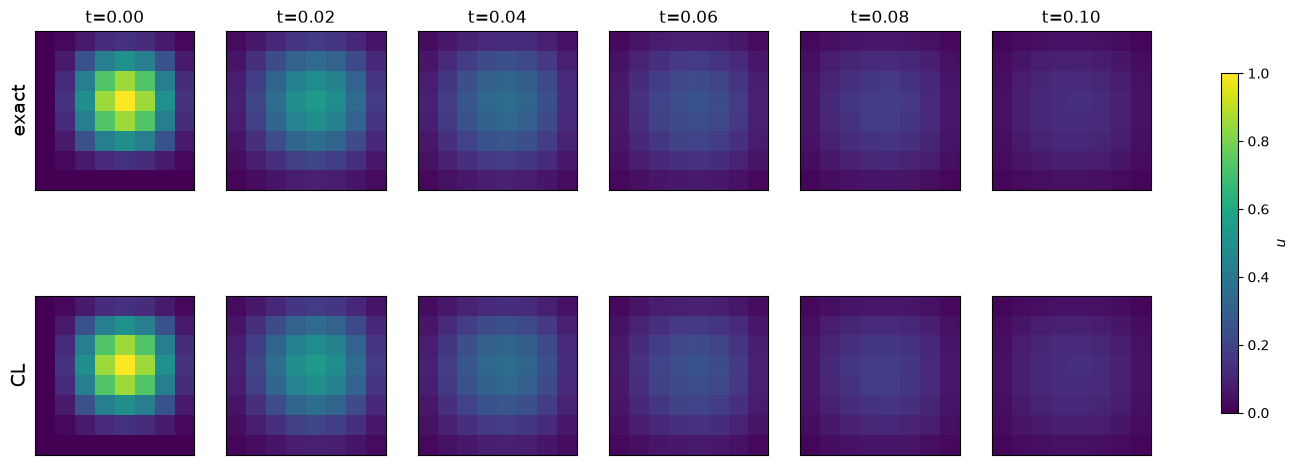

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6.3))
for col, t in enumerate(times):
    for row, (data, label) in enumerate(((exact, "exact"), (cl, "CL"))):
        im = axes[row, col].imshow(data[col], origin="lower", vmin=0, vmax=1, cmap="viridis")
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if row == 0:
            axes[row, col].set_title(f"t={t:.2f}", fontsize=12)
        if col == 0:
            axes[row, col].set_ylabel(label, fontsize=14)
fig.colorbar(im, ax=axes, label=r"$u$", shrink=0.7)
plt.show()

## The same read-out in 2-D

The 1-D version, with the bond counting derived, is in [`kpp_fisher_1d`](kpp_fisher_1d.ipynb).

Nothing about `Vector` is dimension-specific. A grid dof is addressed as `u[a, b]`, and the
structured index carries the coordinate tuple.

The Dirichlet energy now runs over both bond directions:

$$E(t)=\sum_{a,b}\Bigl[\bigl(u_{a,b+1}-u_{a,b}\bigr)^2+\bigl(u_{a+1,b}-u_{a,b}\bigr)^2\Bigr].$$

Same counting as in 1-D. Expanding one bond gives $u_{a,b}^2-2\,u_{a,b}u_{a,b+1}+u_{a,b+1}^2$, so
each site collects a $+1$ on its own square from every bond it belongs to. On a grid a site belongs
to up to four bonds:

$$b_{a,b}=\begin{cases}2,&\text{corner (2 bonds)}\\ 3,&\text{edge (3 bonds)}\\ 4,&\text{interior (4 bonds),}\end{cases}$$

Every bond still contributes $-2$ to its cross term. The cell prints a few coefficients, which lets
you compare a corner, an edge and an interior site.

Still one solve: the same `traj` used for the heatmaps. Only the coefficient vector changes.

In [11]:
energy2d = Vector(
    sum((u[a, b + 1] - u[a, b]) ** 2 for a in range(n) for b in range(n - 1))  # horizontal bonds
    + sum((u[a + 1, b] - u[a, b]) ** 2 for a in range(n - 1) for b in range(n)),  # vertical bonds
    basis,
    u,
)

# on-site squares, then the cross term of every horizontal and vertical bond
support2d = (
    [(((a, b), 2),) for a in range(n) for b in range(n)]
    + [(((a, b), 1), ((a, b + 1), 1)) for a in range(n) for b in range(n - 1)]
    + [(((a, b), 1), ((a + 1, b), 1)) for a in range(n - 1) for b in range(n)]
)
cols2d = [basis.flat_index_of_structured_index(idx) for idx in support2d]
weights2d = np.array([float(energy2d[idx]) for idx in support2d])
def monomial_str(idx):
    return " ".join(f"u_{s}^{p}" if p > 1 else f"u_{s}" for s, p in idx)

coeffs2d = {monomial_str(idx): int(w) for idx, w in zip(support2d, weights2d)}

print(f"{len(coeffs2d)} coefficients; a representative few:")
for note, idx in [
    ("corner, 2 bonds", (((0, 0), 2),)),
    ("edge, 3 bonds", (((0, 3), 2),)),
    ("interior, 4 bonds", (((3, 3), 2),)),
    ("horizontal bond", (((3, 3), 1), ((3, 4), 1))),
    ("vertical bond", (((3, 3), 1), ((4, 3), 1))),
]:
    key = monomial_str(idx)
    print(f"   {{{key}: {coeffs2d[key]:>3d}}}".ljust(46), f"# {note}")

176 coefficients; a representative few:
   {u_(0, 0)^2:   2}                           # corner, 2 bonds
   {u_(0, 3)^2:   3}                           # edge, 3 bonds
   {u_(3, 3)^2:   4}                           # interior, 4 bonds
   {u_(3, 3) u_(3, 4):  -2}                    # horizontal bond
   {u_(3, 3) u_(4, 3):  -2}                    # vertical bond


**The CL energy, from the stored trajectory.** Identical to 1-D: one dot product per time step
against `traj`.

That is the same trajectory the heatmaps above came from, so the observable costs no second solve.

In [12]:
E2_cl = traj[:, cols2d] @ weights2d  # the trajectory behind the heatmaps, reused
print(f"E(0) = {E2_cl[0]:.6f}   E(T) = {E2_cl[-1]:.6f}")

E(0) = 3.386039   E(T) = 0.054683


**The same energy from the nonlinear solve.** Both bond directions again, this time summed over
`exact`, the direct nonlinear 2-D solve from earlier.

In [13]:
E2_exact = ((exact[:, :, 1:] - exact[:, :, :-1]) ** 2).sum((1, 2)) + (
    (exact[:, 1:, :] - exact[:, :-1, :]) ** 2
).sum((1, 2))
print(f"max|CL - exact| = {np.abs(E2_cl - E2_exact).max():.2e}")

max|CL - exact| = 1.97e-02


**Energy decay, log scale.** The two curves separate at late times. Degree 2 is a coarser truncation
than the degree 3 used in 1-D, and $E$ is quadratic in $u$, so the error grows.

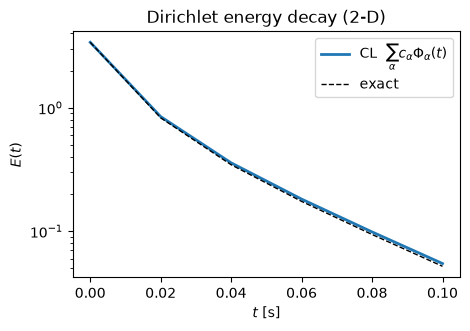

In [14]:
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(times, E2_cl, lw=2, label="CL  $\\sum_\\alpha c_\\alpha \\Phi_\\alpha(t)$")
ax.semilogy(times, E2_exact, "k--", lw=1, label="exact")
ax.set(xlabel="$t$ [s]", ylabel="$E(t)$", title="Dirichlet energy decay (2-D)")
ax.legend()
plt.show()

---

[← KPP–Fisher in 1-D](kpp_fisher_1d.ipynb) · [Notebook index](../README.md) · [KPP–Fisher, position-dependent →](kpp_fisher_position_dependent_1d.ipynb)